In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

print("All imports OK")


All imports OK


In [ ]:
BASE = 'ml-100k/ml-100k/'


ratings = pd.read_csv(BASE + 'u.data', sep='\t',
                      names=['user_id', 'movie_id', 'rating', 'timestamp'])

users = pd.read_csv(BASE + 'u.user', sep='|',
                    names=['user_id', 'age', 'gender', 'occupation', 'zip'])


genre_cols = ['unknown','Action','Adventure','Animation',"Children's",
              'Comedy','Crime','Documentary','Drama','Fantasy',
              'Film-Noir','Horror','Musical','Mystery','Romance',
              'Sci-Fi','Thriller','War','Western']

item_cols = ['movie_id','title','release_date','video_release_date','imdb_url'] + genre_cols

movies = pd.read_csv(BASE + 'u.item', sep='|', names=item_cols, encoding='latin-1')

print(f"Ratings : {ratings.shape}  — columns: {list(ratings.columns)}")
print(f"Users   : {users.shape}  — columns: {list(users.columns)}")
print(f"Movies  : {movies.shape}  — columns: {list(movies.columns[:6])} + 19 genre cols")
print()
print(ratings.head(3))


Ratings : (100000, 4)  — columns: ['user_id', 'movie_id', 'rating', 'timestamp']
Users   : (943, 5)  — columns: ['user_id', 'age', 'gender', 'occupation', 'zip']
Movies  : (1682, 24)  — columns: ['movie_id', 'title', 'release_date', 'video_release_date', 'imdb_url', 'unknown'] + 19 genre cols

   user_id  movie_id  rating  timestamp
0      196       242       3  881250949
1      186       302       3  891717742
2       22       377       1  878887116


In [3]:
n_users  = ratings['user_id'].nunique()
n_movies = ratings['movie_id'].nunique()
n_ratings = len(ratings)
sparsity = 1 - n_ratings / (n_users * n_movies)

stats = pd.DataFrame({
    'Metric': ['Users', 'Movies', 'Total Ratings', 'Min Rating', 'Max Rating',
               'Mean Rating', 'Median Rating', 'Sparsity'],
    'Value':  [n_users, n_movies, n_ratings,
               ratings['rating'].min(), ratings['rating'].max(),
               round(ratings['rating'].mean(), 4),
               ratings['rating'].median(),
               f"{sparsity*100:.2f}%"]
})
print(stats.to_string(index=False))


       Metric   Value
        Users     943
       Movies    1682
Total Ratings  100000
   Min Rating       1
   Max Rating       5
  Mean Rating  3.5299
Median Rating     4.0
     Sparsity  93.70%


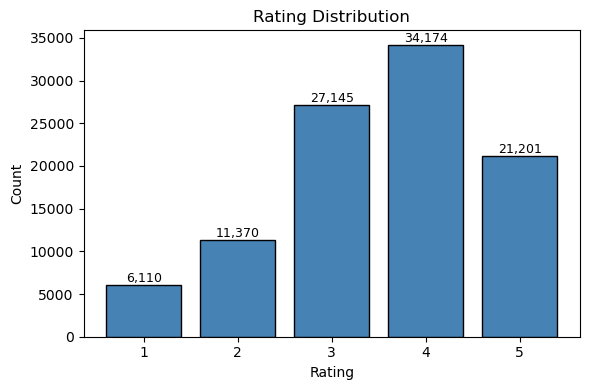

In [4]:
rating_counts = ratings['rating'].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(rating_counts.index, rating_counts.values, color='steelblue', edgecolor='black')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.title('Rating Distribution')
plt.xticks([1, 2, 3, 4, 5])
for i, v in zip(rating_counts.index, rating_counts.values):
    plt.text(i, v + 300, f'{v:,}', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('fig1_rating_dist.png', dpi=150)
plt.show()


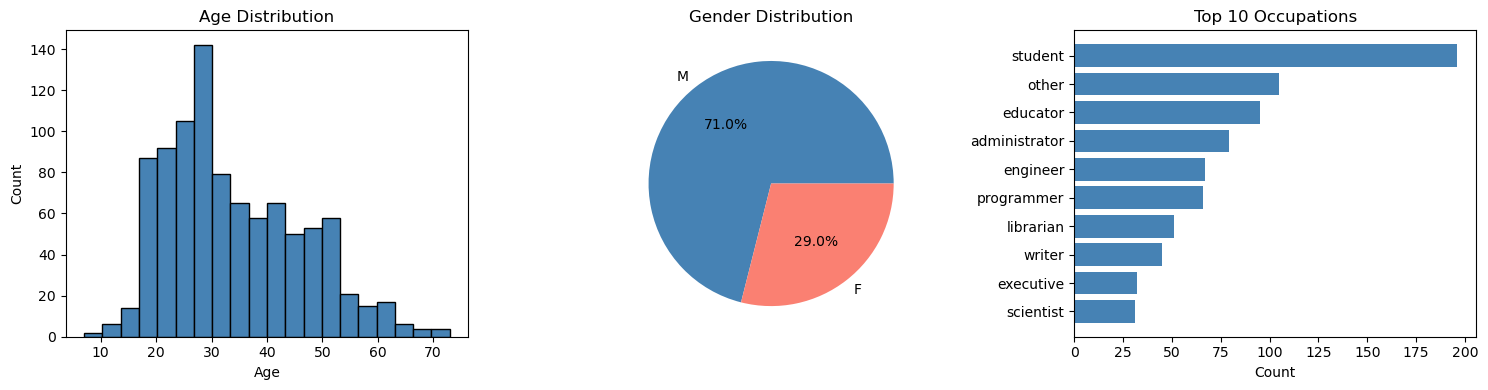

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Age distribution
axes[0].hist(users['age'], bins=20, color='steelblue', edgecolor='black')
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')

# Gender split
gender_counts = users['gender'].value_counts()
axes[1].pie(gender_counts.values, labels=gender_counts.index,
            autopct='%1.1f%%', colors=['steelblue', 'salmon'])
axes[1].set_title('Gender Distribution')

# Top 10 occupations
occ_counts = users['occupation'].value_counts().head(10)
axes[2].barh(occ_counts.index[::-1], occ_counts.values[::-1], color='steelblue')
axes[2].set_title('Top 10 Occupations')
axes[2].set_xlabel('Count')

plt.tight_layout()
plt.savefig('fig2_user_demographics.png', dpi=150)
plt.show()


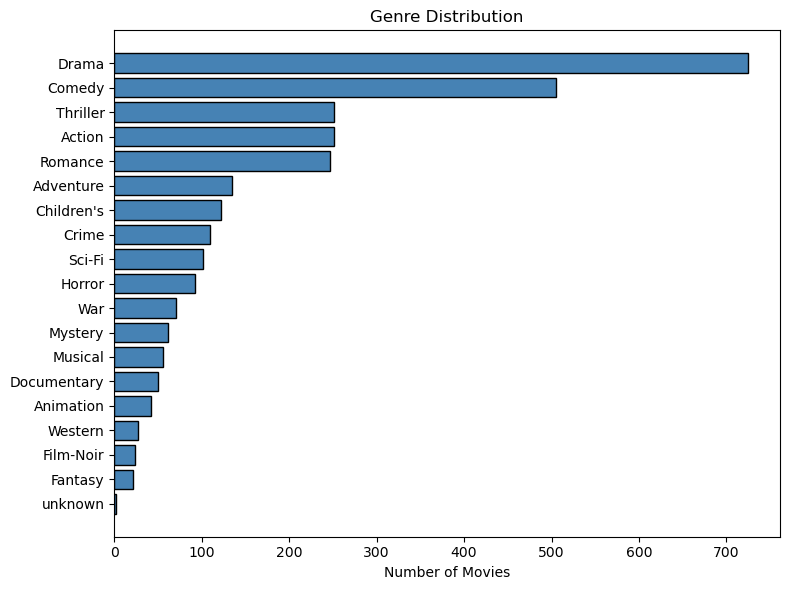

In [6]:
genre_counts = movies[genre_cols].sum().sort_values()

plt.figure(figsize=(8, 6))
plt.barh(genre_counts.index, genre_counts.values, color='steelblue', edgecolor='black')
plt.xlabel('Number of Movies')
plt.title('Genre Distribution')
plt.tight_layout()
plt.savefig('fig3_genre_dist.png', dpi=150)
plt.show()


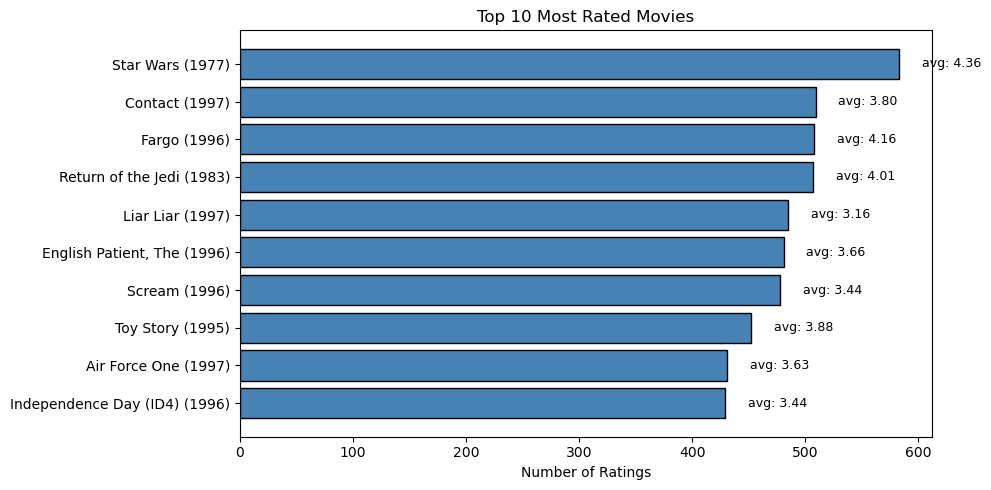

In [7]:
top_movies = (ratings.merge(movies[['movie_id', 'title']], on='movie_id')
                      .groupby('title')
                      .agg(count=('rating','count'), avg_rating=('rating','mean'))
                      .sort_values('count', ascending=False)
                      .head(10))

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(top_movies.index[::-1], top_movies['count'][::-1], color='steelblue', edgecolor='black')
for bar, avg in zip(bars, top_movies['avg_rating'][::-1]):
    ax.text(bar.get_width() + 20, bar.get_y() + bar.get_height()/2,
            f'avg: {avg:.2f}', va='center', fontsize=9)
ax.set_xlabel('Number of Ratings')
ax.set_title('Top 10 Most Rated Movies')
plt.tight_layout()
plt.savefig('fig4_top_movies.png', dpi=150)
plt.show()


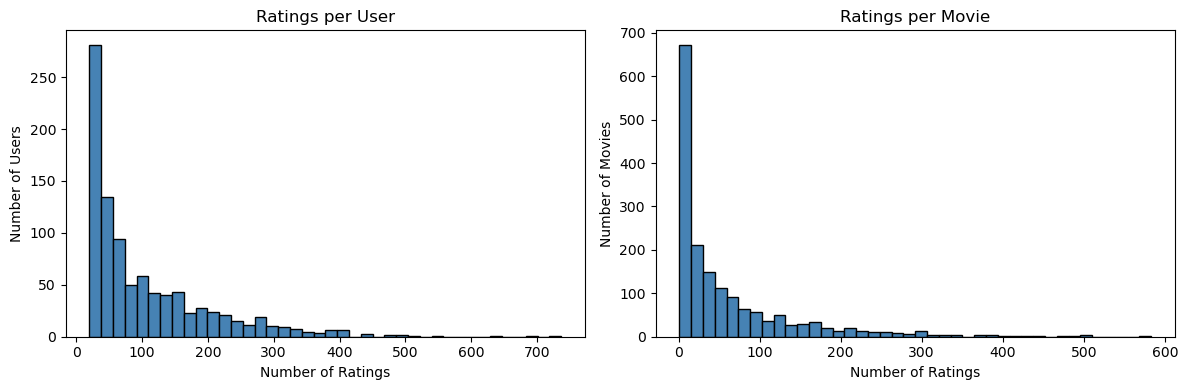

Avg ratings per user : 106.0  |  max: 737
Avg ratings per movie: 59.5  |  max: 583


In [8]:
ratings_per_user  = ratings.groupby('user_id')['rating'].count()
ratings_per_movie = ratings.groupby('movie_id')['rating'].count()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(ratings_per_user, bins=40, color='steelblue', edgecolor='black')
axes[0].set_title('Ratings per User')
axes[0].set_xlabel('Number of Ratings')
axes[0].set_ylabel('Number of Users')

axes[1].hist(ratings_per_movie, bins=40, color='steelblue', edgecolor='black')
axes[1].set_title('Ratings per Movie')
axes[1].set_xlabel('Number of Ratings')
axes[1].set_ylabel('Number of Movies')

plt.tight_layout()
plt.savefig('fig5_activity_dist.png', dpi=150)
plt.show()

print(f"Avg ratings per user : {ratings_per_user.mean():.1f}  |  max: {ratings_per_user.max()}")
print(f"Avg ratings per movie: {ratings_per_movie.mean():.1f}  |  max: {ratings_per_movie.max()}")


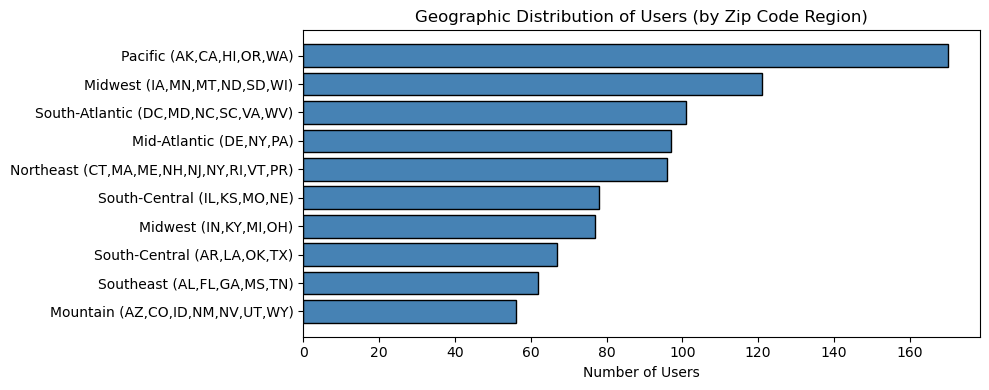

Pacific (AK,CA,HI,OR,WA)                  170
Midwest (IA,MN,MT,ND,SD,WI)               121
South-Atlantic (DC,MD,NC,SC,VA,WV)        101
Mid-Atlantic (DE,NY,PA)                    97
Northeast (CT,MA,ME,NH,NJ,NY,RI,VT,PR)     96
South-Central (IL,KS,MO,NE)                78
Midwest (IN,KY,MI,OH)                      77
South-Central (AR,LA,OK,TX)                67
Southeast (AL,FL,GA,MS,TN)                 62
Mountain (AZ,CO,ID,NM,NV,UT,WY)            56
Name: region, dtype: int64


In [17]:
users['zip_clean'] = users['zip'].astype(str).str.extract(r'^(\d)')[0]
region_map = {
    '0': 'Northeast (CT,MA,ME,NH,NJ,NY,RI,VT,PR)',
    '1': 'Mid-Atlantic (DE,NY,PA)',
    '2': 'South-Atlantic (DC,MD,NC,SC,VA,WV)',
    '3': 'Southeast (AL,FL,GA,MS,TN)',
    '4': 'Midwest (IN,KY,MI,OH)',
    '5': 'Midwest (IA,MN,MT,ND,SD,WI)',
    '6': 'South-Central (IL,KS,MO,NE)',
    '7': 'South-Central (AR,LA,OK,TX)',
    '8': 'Mountain (AZ,CO,ID,NM,NV,UT,WY)',
    '9': 'Pacific (AK,CA,HI,OR,WA)'
}
users['region'] = users['zip_clean'].map(region_map)
region_counts = users['region'].value_counts()

plt.figure(figsize=(10, 4))
plt.barh(region_counts.index[::-1], region_counts.values[::-1], color='steelblue', edgecolor='black')
plt.xlabel('Number of Users')
plt.title('Geographic Distribution of Users (by Zip Code Region)')
plt.tight_layout()
plt.savefig('fig6_zipcode.png', dpi=150)
plt.show()
print(region_counts)


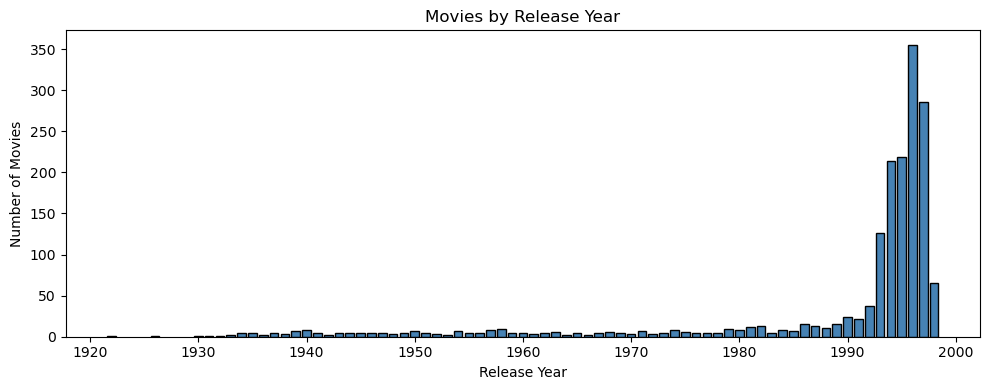

count    1681.00000
mean     1989.38608
std        14.25358
min      1922.00000
25%      1993.00000
50%      1995.00000
75%      1996.00000
max      1998.00000
Name: year, dtype: float64


In [16]:
movies['year'] = pd.to_datetime(movies['release_date'], errors='coerce').dt.year

year_counts = movies['year'].dropna().astype(int).value_counts().sort_index()

plt.figure(figsize=(10, 4))
plt.bar(year_counts.index, year_counts.values, color='steelblue', edgecolor='black')
plt.xlabel('Release Year')
plt.ylabel('Number of Movies')
plt.title('Movies by Release Year')
plt.tight_layout()
plt.savefig('fig6_release_year.png', dpi=150)
plt.show()

print(movies['year'].describe())


In [9]:
N_USERS = ratings['user_id'].max()
N_ITEMS = ratings['movie_id'].max()

data = ratings[['user_id','movie_id','rating']].values.copy().astype(float)
data[:, 0] -= 1
data[:, 1] -= 1

np.random.shuffle(data)
folds = np.array_split(data, 3)

print(f"N_USERS={N_USERS}, N_ITEMS={N_ITEMS}")
print(f"Fold sizes: {[len(f) for f in folds]}")
print(f"Sample row (0-indexed): {data[0]}")


N_USERS=943, N_ITEMS=1682
Fold sizes: [33334, 33333, 33333]
Sample row (0-indexed): [876. 380.   4.]


In [10]:
class MatrixFactorization:
    def __init__(self, n_users, n_items, k=20, alpha=0.005, lam=0.02, n_epochs=30):
        self.k = k
        self.alpha = alpha
        self.lam = lam
        self.n_epochs = n_epochs
        self.P = np.random.normal(0, 0.1, (n_users, k))
        self.Q = np.random.normal(0, 0.1, (n_items, k))

    def predict(self, u, i):
        return float(self.P[u] @ self.Q[i])

    def rmse(self, data):
        errors = [(r - self.predict(int(u), int(i)))**2 for u, i, r in data]
        return float(np.sqrt(np.mean(errors)))

    def fit(self, train, val=None):
        train = np.array(train)
        train_hist, val_hist = [], []
        for epoch in range(self.n_epochs):
            np.random.shuffle(train)
            for u, i, r in train:
                u, i = int(u), int(i)
                e = r - self.predict(u, i)
                pu = self.P[u].copy()
                self.P[u] += self.alpha * (e * self.Q[i] - self.lam * self.P[u])
                self.Q[i] += self.alpha * (e * pu       - self.lam * self.Q[i])
            train_hist.append(self.rmse(train))
            if val is not None:
                val_hist.append(self.rmse(val))
        return train_hist, val_hist

print("MatrixFactorization class defined.")


MatrixFactorization class defined.


In [11]:
train_gs = np.concatenate([folds[0], folds[1]])
val_gs   = folds[2]

mu = train_gs[:, 2].mean()
train_gs_norm = train_gs.copy(); train_gs_norm[:, 2] -= mu
val_gs_norm   = val_gs.copy();   val_gs_norm[:, 2]   -= mu

param_grid = {'k': [10, 20, 50], 'alpha': [0.01, 0.005], 'lam': [0.05, 0.01]}

results = []
total = len(param_grid['k']) * len(param_grid['alpha']) * len(param_grid['lam'])
count = 0

for k in param_grid['k']:
    for alpha in param_grid['alpha']:
        for lam in param_grid['lam']:
            count += 1
            mf = MatrixFactorization(N_USERS, N_ITEMS, k=k, alpha=alpha, lam=lam, n_epochs=20)
            mf.fit(train_gs_norm)
            v_rmse = mf.rmse(val_gs_norm)
            results.append({'k': k, 'alpha': alpha, 'lam': lam, 'val_rmse': round(v_rmse, 4)})
            print(f"[{count}/{total}] k={k}, alpha={alpha}, lam={lam} -> val RMSE={v_rmse:.4f}")

results_df = pd.DataFrame(results).sort_values('val_rmse')
print("\nTop 5:")
print(results_df.head(5).to_string(index=False))


[1/12] k=10, alpha=0.01, lam=0.05 -> val RMSE=0.9531
[2/12] k=10, alpha=0.01, lam=0.01 -> val RMSE=0.9677
[3/12] k=10, alpha=0.005, lam=0.05 -> val RMSE=1.0433
[4/12] k=10, alpha=0.005, lam=0.01 -> val RMSE=1.0167
[5/12] k=20, alpha=0.01, lam=0.05 -> val RMSE=0.9574
[6/12] k=20, alpha=0.01, lam=0.01 -> val RMSE=0.9905
[7/12] k=20, alpha=0.005, lam=0.05 -> val RMSE=1.0120
[8/12] k=20, alpha=0.005, lam=0.01 -> val RMSE=1.0026
[9/12] k=50, alpha=0.01, lam=0.05 -> val RMSE=0.9610
[10/12] k=50, alpha=0.01, lam=0.01 -> val RMSE=1.0216
[11/12] k=50, alpha=0.005, lam=0.05 -> val RMSE=1.0001
[12/12] k=50, alpha=0.005, lam=0.01 -> val RMSE=1.0071

Top 5:
 k  alpha  lam  val_rmse
10   0.01 0.05    0.9531
20   0.01 0.05    0.9574
50   0.01 0.05    0.9610
10   0.01 0.01    0.9677
20   0.01 0.01    0.9905


In [12]:
best_k, best_alpha, best_lam = 10, 0.01, 0.05
test_rmses = []

for fold_idx in range(3):
    test  = folds[fold_idx]
    train = np.concatenate([folds[j] for j in range(3) if j != fold_idx])

    mu = train[:, 2].mean()
    train_norm = train.copy(); train_norm[:, 2] -= mu
    test_norm  = test.copy();  test_norm[:, 2]  -= mu

    mf = MatrixFactorization(N_USERS, N_ITEMS, k=best_k, alpha=best_alpha,
                             lam=best_lam, n_epochs=30)
    mf.fit(train_norm)
    rmse = mf.rmse(test_norm)
    test_rmses.append(rmse)
    print(f"Fold {fold_idx+1}: test RMSE = {rmse:.4f}")

print(f"\nMean RMSE : {np.mean(test_rmses):.4f}")
print(f"Std  RMSE : {np.std(test_rmses):.4f}")


Fold 1: test RMSE = 0.9476
Fold 2: test RMSE = 0.9552
Fold 3: test RMSE = 0.9552

Mean RMSE : 0.9526
Std  RMSE : 0.0036


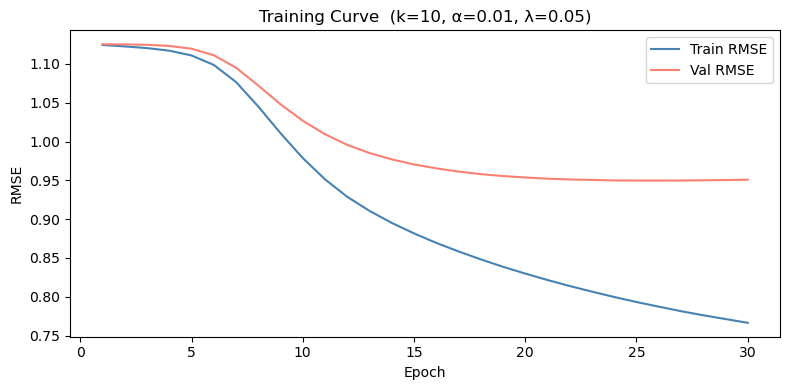

In [13]:
train_plot = np.concatenate([folds[0], folds[1]])
val_plot   = folds[2]

mu = train_plot[:, 2].mean()
train_plot_norm = train_plot.copy(); train_plot_norm[:, 2] -= mu
val_plot_norm   = val_plot.copy();   val_plot_norm[:, 2]   -= mu

mf_best = MatrixFactorization(N_USERS, N_ITEMS, k=best_k, alpha=best_alpha,
                               lam=best_lam, n_epochs=30)
train_hist, val_hist = mf_best.fit(train_plot_norm, val=val_plot_norm)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 31), train_hist, label='Train RMSE', color='steelblue')
plt.plot(range(1, 31), val_hist,   label='Val RMSE',   color='salmon')
plt.xlabel('Epoch')
plt.ylabel('RMSE')
plt.title(f'Training Curve  (k={best_k}, α={best_alpha}, λ={best_lam})')
plt.legend()
plt.tight_layout()
plt.savefig('fig6_training_curve.png', dpi=150)
plt.show()


In [21]:
from sklearn.decomposition import NMF

def build_matrix(data, n_users, n_items, fill_val):
    mat = np.full((n_users, n_items), fill_val)
    for u, i, r in data:
        mat[int(u), int(i)] = r
    return mat

train_nmf_gs = np.concatenate([folds[0], folds[1]])
val_nmf_gs   = folds[2]
mu_nmf       = train_nmf_gs[:, 2].mean()
mat_nmf_gs   = build_matrix(train_nmf_gs, N_USERS, N_ITEMS, fill_val=mu_nmf)

nmf_grid = {'k': [5, 10, 20], 'alpha': [0.01, 0.05, 0.1]}
nmf_gs_results = []
total = len(nmf_grid['k']) * len(nmf_grid['alpha'])
count = 0

for k in nmf_grid['k']:
    for alpha in nmf_grid['alpha']:
        count += 1
        nmf = NMF(n_components=k, solver='cd', alpha_W=alpha, alpha_H=alpha,
                  l1_ratio=0.0, max_iter=300, random_state=42)
        W = nmf.fit_transform(mat_nmf_gs)
        H = nmf.components_
        pred = W @ H
        sq = [(r - pred[int(u), int(i)])**2 for u, i, r in val_nmf_gs]
        rmse = float(np.sqrt(np.mean(sq)))
        nmf_gs_results.append({'k': k, 'alpha': alpha, 'val_rmse': round(rmse, 4)})
        print(f"[{count}/{total}] k={k}, alpha={alpha} -> val RMSE={rmse:.4f}")

nmf_gs_df = pd.DataFrame(nmf_gs_results).sort_values('val_rmse')
print("\nTop 3:")
print(nmf_gs_df.head(3).to_string(index=False))


[1/9] k=5, alpha=0.01 -> val RMSE=1.0666
[2/9] k=5, alpha=0.05 -> val RMSE=1.0899
[3/9] k=5, alpha=0.1 -> val RMSE=1.0933
[4/9] k=10, alpha=0.01 -> val RMSE=1.0628
[5/9] k=10, alpha=0.05 -> val RMSE=1.0900
[6/9] k=10, alpha=0.1 -> val RMSE=1.0938
[7/9] k=20, alpha=0.01 -> val RMSE=1.0922
[8/9] k=20, alpha=0.05 -> val RMSE=1.0898
[9/9] k=20, alpha=0.1 -> val RMSE=1.0918

Top 3:
 k  alpha  val_rmse
10   0.01    1.0628
 5   0.01    1.0666
20   0.05    1.0898


In [ ]:
best_nmf_k, best_nmf_alpha = 10, 0.01
nmf_results = []

for fold_idx in range(3):
    test  = folds[fold_idx]
    train = np.concatenate([folds[j] for j in range(3) if j != fold_idx])

    mu  = train[:, 2].mean()
    mat = build_matrix(train, N_USERS, N_ITEMS, fill_val=mu)

    nmf = NMF(n_components=best_nmf_k, solver='cd', alpha_W=best_nmf_alpha,
              alpha_H=best_nmf_alpha, l1_ratio=0.0, max_iter=300, random_state=42)
    W = nmf.fit_transform(mat)
    H = nmf.components_
    pred = W @ H

    sq = [(r - pred[int(u), int(i)])**2 for u, i, r in test]
    rmse = float(np.sqrt(np.mean(sq)))
    nmf_results.append(rmse)
    print(f"Fold {fold_idx+1}: test RMSE = {rmse:.4f}")

print(f"\nMean RMSE : {np.mean(nmf_results):.4f}")
print(f"Std  RMSE : {np.std(nmf_results):.4f}")


Fold 1: test RMSE = 1.0606
Fold 2: test RMSE = 1.0654
Fold 3: test RMSE = 1.0628

Mean RMSE : 1.0629
Std  RMSE : 0.0020


                Method  Mean RMSE Std RMSE
      SGD-MF (scratch)     0.9526   0.0036
      NMF-CD (sklearn)     1.0629    0.002
Baseline (global mean)     1.1257        -


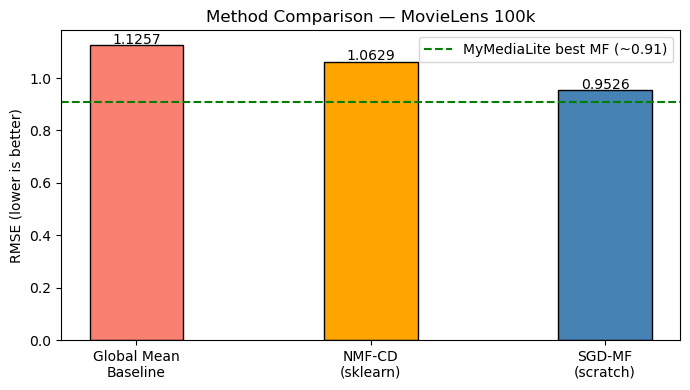

In [20]:
comparison = pd.DataFrame({
    'Method':    ['SGD-MF (scratch)', 'NMF-CD (sklearn)', 'Baseline (global mean)'],
    'Mean RMSE': [round(np.mean(test_rmses), 4),
                  round(np.mean(nmf_results), 4),
                  round(float(np.sqrt(np.mean((data[:,2] - data[:,2].mean())**2))), 4)],
    'Std RMSE':  [round(np.std(test_rmses), 4),
                  round(np.std(nmf_results), 4),
                  '-']
})
print(comparison.to_string(index=False))

plt.figure(figsize=(7, 4))
methods = ['Global Mean\nBaseline', 'NMF-CD\n(sklearn)', 'SGD-MF\n(scratch)']
rmses   = [comparison['Mean RMSE'][2], np.mean(nmf_results), np.mean(test_rmses)]
colors  = ['salmon', 'orange', 'steelblue']
bars = plt.bar(methods, rmses, color=colors, edgecolor='black', width=0.4)
for bar, val in zip(bars, rmses):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.4f}', ha='center', fontsize=10)
plt.axhline(y=0.91, color='green', linestyle='--', label='MyMediaLite best MF (~0.91)')
plt.ylabel('RMSE (lower is better)')
plt.title('Method Comparison — MovieLens 100k')
plt.legend()
plt.tight_layout()
plt.savefig('fig9_comparison.png', dpi=150)
plt.show()
